# 01: Exploring the public dataset (collar)

Goal: **look** at the data before training anything. See how each behavior shows up in the
collar signal, how much data each class has, and whether the classes look separable.

- Data: Vehkaoja et al. (2022) / Kumpulainen et al. (2021). Details in `docs/public-dataset.md`.
- Neck sensor only, resampled to 50 Hz and saturated at ±16 g / ±2000 dps (ADR 0005).
- All logic lives in `coleira_ml.public_dataset`. This notebook only explores.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from coleira_ml.classes import Behavior
from coleira_ml.public_dataset import TARGET_HZ, load_collar

df = load_collar(Path("../data/public"))
df["acc_mag"] = np.sqrt(df.ax**2 + df.ay**2 + df.az**2)  # 7th channel, contract 4.3
df["gyro_mag"] = np.sqrt(df.gx**2 + df.gy**2 + df.gz**2)
KNOWN = [b for b in Behavior if b != Behavior.UNKNOWN and (df.class_id == b).any()]
COLORS = dict(zip(KNOWN, plt.cm.tab10.colors, strict=False))
print(f"{len(df):,} samples at {TARGET_HZ} Hz = {len(df) / TARGET_HZ / 3600:.1f} h;")
print(f"{df.dog_id.nunique()} dogs")

5,305,534 samples at 50 Hz = 29.5 h;
45 dogs


## How much data per class

In [2]:
summary = pd.DataFrame(
    {
        "minutes": df.groupby("class_id").size() / TARGET_HZ / 60,
        "dogs": df.groupby("class_id").dog_id.nunique(),
    }
)
summary.index = [Behavior(i).name.lower() for i in summary.index]
summary.round(1).sort_values("minutes", ascending=False)

,minutes,dogs
unknown,909.9,45
still,500.2,45
running,156.0,45
walking,139.0,45
eating,45.7,42
drinking,10.8,35
shaking,7.0,45


## One stretch of each behavior

6 seconds from the middle of the first long-enough stretch of each class. Top row:
accelerometer (g), with the magnitude in black. Bottom row: gyroscope (°/s).

What to look for: still is almost flat (just gravity), walking and running are periodic
with different rhythms, and shaking is a short, huge burst, especially on the gyro.

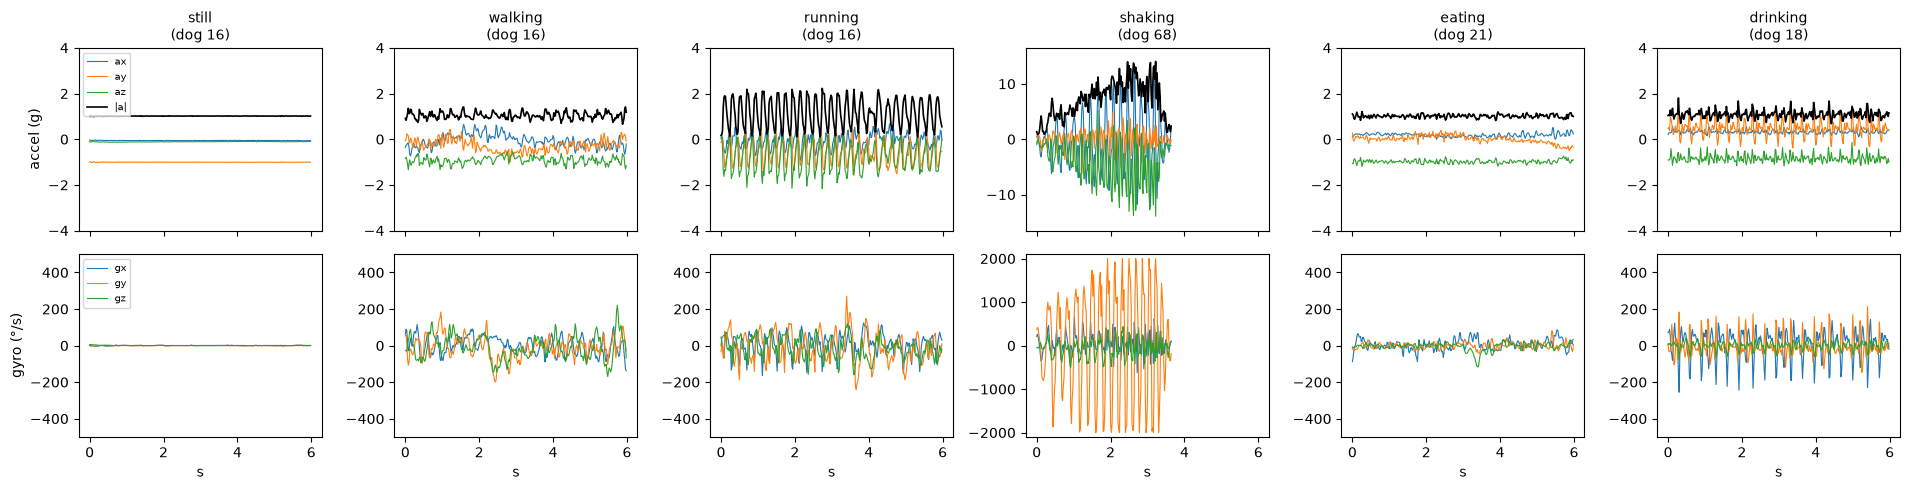

In [3]:
def first_run(cls, seconds=6):
    n = seconds * TARGET_HZ
    is_cls = (df.class_id == cls).to_numpy()
    seg_id = (df.class_id != df.class_id.shift()).cumsum()
    for _, g in df[is_cls].groupby(seg_id[is_cls]):
        if len(g) >= n:
            mid = len(g) // 2
            return g.iloc[max(0, mid - n // 2) : max(0, mid - n // 2) + n]
    g = df[is_cls].groupby(seg_id[is_cls]).size().idxmax()
    return df[is_cls][seg_id[is_cls] == g]


fig, axes = plt.subplots(2, len(KNOWN), figsize=(3.2 * len(KNOWN), 5), sharex=True)
for j, cls in enumerate(KNOWN):
    seg = first_run(cls)
    t = np.arange(len(seg)) / TARGET_HZ
    for c in ["ax", "ay", "az"]:
        axes[0, j].plot(t, seg[c], lw=0.8, label=c)
    axes[0, j].plot(t, seg.acc_mag, "k", lw=1.2, label="|a|")
    for c in ["gx", "gy", "gz"]:
        axes[1, j].plot(t, seg[c], lw=0.8, label=c)
    axes[0, j].set_title(f"{Behavior(cls).name.lower()}\n(dog {seg.dog_id.iloc[0]})", fontsize=10)
    big = cls == Behavior.SHAKING
    axes[0, j].set_ylim(*((-16.5, 16.5) if big else (-4, 4)))
    axes[1, j].set_ylim(*((-2100, 2100) if big else (-500, 500)))
    axes[1, j].set_xlabel("s")
axes[0, 0].set_ylabel("accel (g)")
axes[1, 0].set_ylabel("gyro (°/s)")
axes[0, 0].legend(fontsize=7, loc="upper left")
axes[1, 0].legend(fontsize=7, loc="upper left")
fig.tight_layout()

## Intensity: standard deviation of the magnitude in 2 s windows

A single feature (how much the acceleration magnitude varies over 2 s) already separates
still / walking / running / shaking well. Eating and drinking overlap with still, which is
why they need more than intensity (and why they are Phase 6).

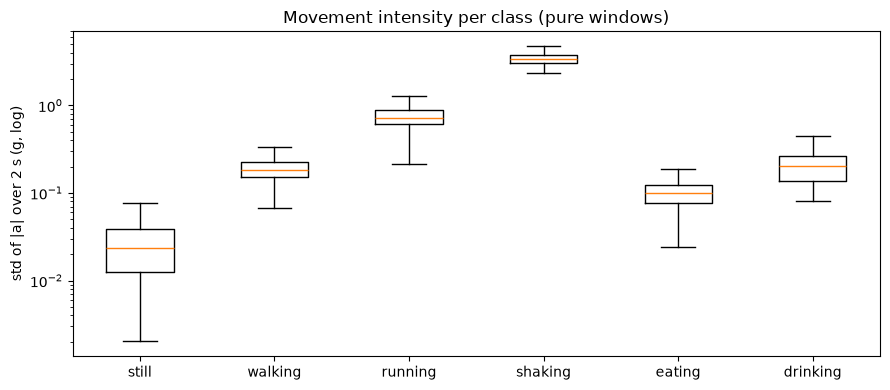

In [4]:
W = 2 * TARGET_HZ
d = df[df.class_id != Behavior.UNKNOWN].copy()
d["win"] = d.groupby(["dog_id", "test_num"]).cumcount() // W
grp = d.groupby(["dog_id", "test_num", "win"])
win = grp.agg(cls=("class_id", "first"), pure=("class_id", "nunique"), std=("acc_mag", "std"))
win = win[win.pure == 1]

fig, ax = plt.subplots(figsize=(9, 4))
data = [win[win.cls == c]["std"].clip(lower=1e-3) for c in KNOWN]
ax.boxplot(data, tick_labels=[Behavior(c).name.lower() for c in KNOWN], showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("std of |a| over 2 s (g, log)")
ax.set_title("Movement intensity per class (pure windows)")
fig.tight_layout()

## Rhythm: spectrum of the magnitude per class

Average spectrum (Welch) of |a| per class.

Gotcha: the **magnitude** |a| oscillates at **twice** the frequency of the movement. A
swing to one side and back produces two peaks of |a|, since the sign (+/−) disappears.
So a ~2 Hz stride shows up at ~4 Hz, and a ~5 Hz shake shows up at ~10 Hz.

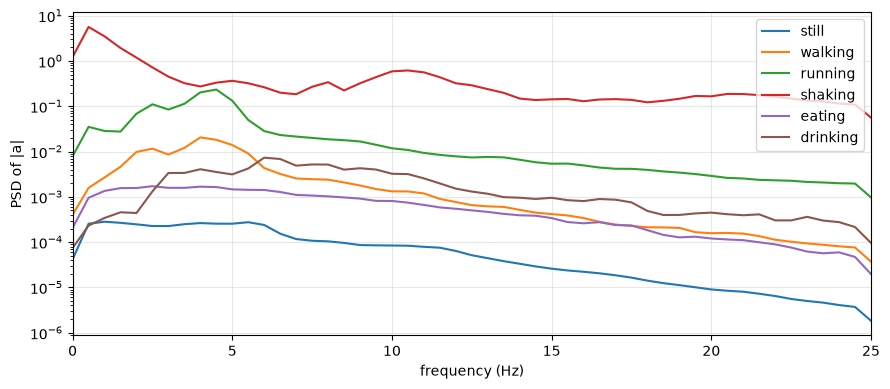

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for cls in KNOWN:
    psds = []
    for _, g in d[d.class_id == cls].groupby(["dog_id", "test_num"]):
        x = g.acc_mag.to_numpy()
        if len(x) >= W:
            f, p = welch(x - x.mean(), fs=TARGET_HZ, nperseg=W)
            psds.append(p)
    ax.semilogy(f, np.mean(psds, axis=0), label=Behavior(cls).name.lower(), color=COLORS[cls])
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("PSD of |a|")
ax.set_xlim(0, 25)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## Shake durations (for ADR 0002)

In [6]:
seg = (
    (df.class_id != df.class_id.shift())
    | (df.dog_id != df.dog_id.shift())
    | (df.test_num != df.test_num.shift())
).cumsum()
runs = df.assign(seg=seg).groupby("seg").agg(cls=("class_id", "first"), n=("class_id", "size"))
shake_s = runs[runs.cls == Behavior.SHAKING].n / TARGET_HZ
print(f"{len(shake_s)} shakes")
shake_s.describe(percentiles=[0.1, 0.5, 0.9]).round(2)

286 shakes


count    286.00
mean       1.46
std        0.69
min        0.06
10%        0.62
50%        1.42
90%        2.42
max        3.66
Name: n, dtype: float64

## Conclusions (2026-11-16)

1. **Intensity alone already separates 0 → 1 → 2 → 4.** The std of |a| over 2 s grows ~10×
   at each step: still ~0.02 g, walking ~0.2 g, running ~0.7 g, shaking ~3.5 g. The boxes
   barely overlap, a good sign for the Phase 0 target of ≥ 85%.
2. **Shaking is unmistakable:** |a| reaches 10–15 g and the gyro **saturates at
   ±2000 °/s**, as predicted in ADR 0005. Median duration **1.4 s** (90% < 2.4 s), which
   confirms ADR 0002's premise: a 5-window majority would erase these events.
3. **Walking × running:** both peak at ~4 Hz in |a| (stride ~2 Hz), but running has ~10×
   more energy. The rhythm is similar; the force is what changes.
4. **Eating overlaps with still and walking** in intensity (~0.1 g). It needs another cue
   (head posture, chewing pattern, audio), which confirms why it was left for Phase 6.
5. **Drinking has its own signature:** a peak at ~6 Hz in the spectrum, probably lapping.
   More promising than eating.
6. **Strong imbalance:** 500 min of still vs 7 min of shaking. We need class weights and
   must look at per-class F1 and balanced accuracy, never plain accuracy.